Projeto Integrador II • PUC-SP

# 1. Problema proposto

A preparação dos dados foi orientada pela tarefa de triagem inteligente de chamados de suporte de TI.
Objetivo
Classificar automaticamente os chamados em seis categorias:
- Software
- Rede
- Hardware
- RH
- Acesso
- Financeiro
Entradas multimodais
Modalidade	Informação utilizada	Papel esperado
PLN	Título e descrição do chamado	Extrair sinais semânticos, contexto e intenção
Visão Computacional	Imagens anexadas	Gerar descrições e representações visuais
Dados tabulares	Atributos estruturados selecionados	Fornecer contexto técnico adicional


A saída esperada é a categoria prevista para cada chamado.

| Modalidade | Informação utilizada | Papel esperado |
|---|---|---|
| **PLN** | Título e descrição do chamado | Contexto, intenção, palavras-chave |
| **Visão Computacional** | Imagens anexadas | Gerar descrições e representações visuais |
| **Dados tabulares** | Atributos estruturados selecionados | Fornecer contexto técnico adicional |

In [ ]:
from pathlib import Path
import pandas as pd

RAW_PATH = Path("../data/raw/chamados.csv")
CLEAN_PATH = Path("../data/clean/chamados-clean.csv")
PROCESSED_PATH = Path("../data/processed/chamados.parquet")

print("Arquivos encontrados:")
for path in [RAW_PATH, CLEAN_PATH, PROCESSED_PATH]:
    print(f"{path}: {path.exists()}")

Arquivos encontrados:
..\data\raw\chamados.csv: True
..\data\clean\chamados-clean.csv: True
..\data\processed\chamados.parquet: True


# 2. Dataset

Valores observados no CSV tratado e no notebook exploratório.
| Indicador | Quantidade |
|---|---:|
| Registros | **5.000** |
| Colunas originais | **44** |
| Colunas processadas | **19** |
| Categorias-alvo | **6** |

In [4]:
# Inspeção básica da base processada
if PROCESSED_PATH.exists():
    df = pd.read_parquet(PROCESSED_PATH)
    print("Dimensões:", df.shape)
    display(df.head())
    display(df.dtypes)
else:
    print("Arquivo Parquet não encontrado. Confira o caminho PROCESSED_PATH.")

Dimensões: (5000, 19)


,ticket_id,department,device_type,os,network_type,sla_hours,resolution_time_hours,title,description,image_path,image_width,image_height,priority,status,assigned_team,sentiment_score,num_words,num_images_x,target_category
0,1,Operações,Desktop,Windows,WiFi,4.0,28.0,Falha crítica no teclado: não funciona com tel...,Falha crítica no teclado: não funciona com tel...,images/keyboard.png,500,375,Alta,Fechado,N2,-0.559,6.0,2,Hardware
1,2,Financeiro,Notebook,Windows,5G,12.0,45.0,Falha no sistema de folha ao tentar gerar rela...,Falha no sistema de folha ao tentar gerar rela...,images/payroll.png,612,408,Crítica,Fechado,Aplicações,0.946,6.0,3,RH
2,3,TI,Desktop,Linux,5G,24.0,47.0,O Sistema de tesouraria exibe cheiro de queima...,O Sistema de tesouraria exibe cheiro de queima...,images/finance_report.png,738,414,Média,Em andamento,N2,0.404,6.0,0,Financeiro
3,4,Financeiro,Mobile,Android,Cabo,12.0,52.0,O aplicativo Sistema ERP fecha inesperadamente...,O aplicativo Sistema ERP fecha inesperadamente...,images/sap_erp.png,612,344,Crítica,Aberto,Infra,0.311,3.0,3,Software
4,5,Financeiro,Mobile,iOS,Cabo,48.0,64.0,O acesso à banco de dados falha com reinicia s...,O acesso à banco de dados falha com reinicia s...,images/server.png,500,333,Média,Aberto,N2,0.584,6.0,3,Rede


ticket_id                    str
department                   str
device_type                  str
os                           str
network_type                 str
sla_hours                Float64
resolution_time_hours    Float64
title                        str
description                  str
image_path                   str
image_width                int64
image_height               int64
priority                     str
status                       str
assigned_team                str
sentiment_score          Float64
num_words                Float64
num_images_x               int64
target_category              str
dtype: object

In [12]:
# Valores ausentes, diferentes e constantes
if PROCESSED_PATH.exists():
    diagnostico = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "percentual_nulos": (df.isna().mean() * 100).round(2),
        "valores_distintos": df.nunique(dropna=True),
        "constante": df.nunique(dropna=True).le(1)
    }).sort_values(["percentual_nulos", "valores_distintos"], ascending=[False, True])
    display(diagnostico)

,dtype,nulos,percentual_nulos,valores_distintos,constante
device_type,str,0,0.0,3,False
status,str,0,0.0,3,False
department,str,0,0.0,4,False
os,str,0,0.0,4,False
network_type,str,0,0.0,4,False
priority,str,0,0.0,4,False
assigned_team,str,0,0.0,4,False
num_images_x,int64,0,0.0,4,False
sla_hours,Float64,0,0.0,5,False
image_width,int64,0,0.0,5,False


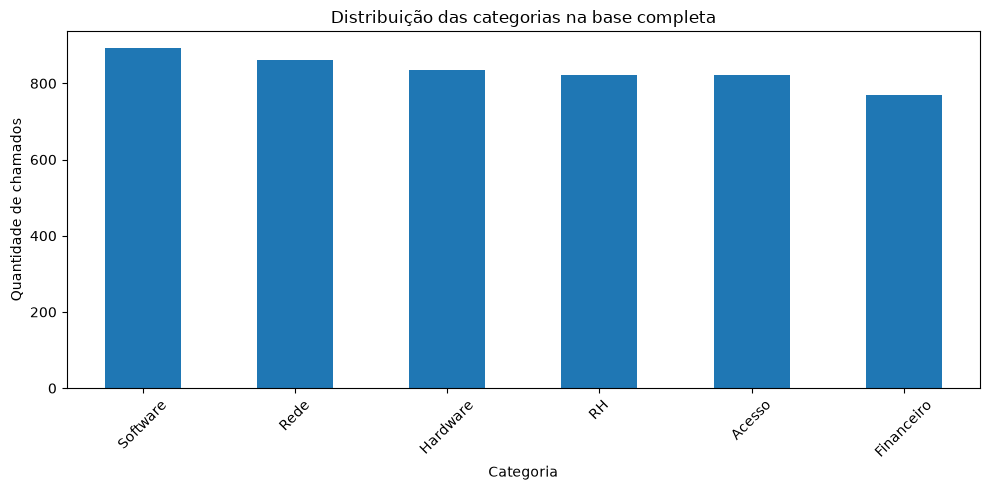

In [13]:
import matplotlib.pyplot as plt

df['target_category'].value_counts().plot(
    kind='bar',
    figsize=(10, 5),
    title='Distribuição das categorias na base completa'
)

plt.xlabel('Categoria')
plt.ylabel('Quantidade de chamados')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [15]:
# Distribuição das categorias do alvo
if PROCESSED_PATH.exists() and "target_category" in df.columns:
    distribuicao = (
        df["target_category"]
        .value_counts(dropna=False)
        .rename_axis("categoria")
        .to_frame("registros")
    )
    distribuicao["percentual"] = (
        distribuicao["registros"] / len(df) * 100
    ).round(2)
    display(distribuicao)


,registros,percentual
categoria,,
Software,892,17.84
Rede,861,17.22
Hardware,835,16.70
RH,821,16.42
Acesso,821,16.42
Financeiro,770,15.40


> Notamos que a distribuição das seis classes é bastante equilibrada.

# 3. Ingestão e Limpeza dos dados
O fluxo separa o arquivo bruto, a base limpa e a base processada.

A limpeza dos dados no arquivo bruto é realizada 

> data/raw/chamados.csv -> cleaner.py

O processamento prepara as informações que realmente serão utilizadas pelo modelo.

> data/clean/chamados-clean.csv -> processor.py

> data/processed/chamados.parquet


- Remoção de linhas totalmente vazias e duplicatas exatas.
- Padronização dos nomes das colunas e remoção de espaços nas strings.
- Conversão de strings vazias em valores ausentes.
- Tentativa de inferência de tipos.
Resultado observado nesta versão
O arquivo bruto e o arquivo limpo mantêm 5.000 linhas × 44 colunas, e seus valores são idênticos. Portanto, embora as rotinas de limpeza estejam implementadas, elas não precisaram alterar os registros desta base específica.

As features foram selecionados em `src/config/sources.yaml`, por meio da configuração `drop_cols`, facilitando rastreabilidade e revisão.

Pensamos em remover as features baseando-se em:

1. Irrelevância para o objetivo: colunas que não contribuem para a tarefa de IA.
`latitude`,`longitude`, `customer_id`, `browser`, `created_at`
2. Redundância: colunas que repetem informações ou representam dados já contemplados por outras variáveis.
`city_x`, `state_x`, `historical_tickets`, `num_abertura`, `num_updates`, `has_attachment`
3. Risco metodológico: colunas que podem gerar vieses, vazamento de dados ou problemas de generalização.
`num_events`, `num_encerramento`
4. Feature sem informação: colunas NaN
`company`, `segment`, `employees`, `city_y`, `state_y`, `contract_type`, `customer_since`, `vip`, `monthly_revenue`, `last_event_date`, `event_types`, `num_images_y`

Das 44 colunas, selecionamos apenas 19.

# 4. Particionamento: treino, validação e teste
A configuração está registrada em models.yaml e armazenado os dados em data/processed/splits/chamados.json.

| Partição | Registros | Proporção |
|---|---:|---:|
| Treino | 3.505 | 70,1% |
| Validação | 737 | 14,7% |
| Teste | 758 | 15,2% |
| **Total** | **5.000** | **100%** |


Proporções configuradas: 70% / 15% / 15%.

Objetivo: impedir que a mesma imagem apareça em partições diferentes.